# EfficientNetV2-S for cats and dogs
**Hazem Daw · ITMO Machine Learning Technologies · Task 4, optional contest**

The previous course-trained classifier achieved 2,449 correct predictions on 2,500 test images (97.96%). This experiment measures whether a different convolutional architecture trained from random weights can improve that score. Exceeding 0.9888 requires 2,473 correct predictions.

The completed notebook includes outputs and figures. To reproduce the evaluation, extract the companion ZIP and run the cells in order. The ZIP includes the course-trained checkpoints and complete epoch logs. To repeat training, set `RUN` to a new directory and leave the three reference weights in their supplied folder. Set `DATA_ROOT` to the supplied Cats_and_Dogs folder or let the notebook retrieve the original archive. The notebook uses Python 3.11, PyTorch, torchvision, pandas, NumPy, Pillow, matplotlib, Jupyter and gdown.

In [1]:
from pathlib import Path
import hashlib
import json
import os
import shutil
import zipfile

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display

DATA_ROOT = Path(os.environ.get("ITMO_CATS_DOGS", "../MLT_Task_4/data/Cats_and_Dogs"))
RUN = Path(os.environ.get("ITMO_EFFICIENTNET_RUN", "efficientnet_runtime"))
REFERENCE_WEIGHTS = Path(os.environ.get("ITMO_REFERENCE_WEIGHTS", "reference_weights"))
if not REFERENCE_WEIGHTS.is_dir():
    available = Path("../Task_4_Texture_Experiment/weights")
    if available.is_dir():
        REFERENCE_WEIGHTS = available
FILE_ID = "1lPLlLKhRXvtCG4SNXYflIiy09DMqqPkN"
ARCHIVE_SHA256 = "540915915226479357a1e738bd920c3e19e5a3d8fc56c0622dffa5d682e3631c"
RUN.mkdir(parents=True, exist_ok=True)
get_ipython().run_line_magic("matplotlib", "inline")

In [2]:
def prepare(root):
    root = Path(root).resolve()
    root.mkdir(parents=True, exist_ok=True)
    destination = root / 'Cats_and_Dogs'
    marker = root / 'extraction.json'
    if marker.exists():
        metadata = json.loads(marker.read_text())
        images = [p for p in destination.rglob('*') if p.suffix.lower() in {'.jpg', '.jpeg', '.png'}]
        if len(images) == metadata['images']:
            return destination
        raise ValueError('Extracted dataset is incomplete. Restore the original archive before continuing.')
    archive = root / 'Cats_and_Dogs.zip'
    if not archive.exists():
        import gdown
        gdown.download(id=FILE_ID, output=str(archive), quiet=False)
    if not zipfile.is_zipfile(archive):
        raise ValueError('Download is not a complete ZIP archive.')
    archive_digest = hashlib.sha256(archive.read_bytes()).hexdigest()
    if archive_digest != ARCHIVE_SHA256:
        raise ValueError('Course archive differs from the recorded experiment; check its source/version.')
    with zipfile.ZipFile(archive) as zf:
        for member in zf.infolist():
            parts = Path(member.filename).parts
            if 'Cats_and_Dogs' not in parts or '__MACOSX' in parts:
                continue
            parts = parts[parts.index('Cats_and_Dogs') + 1:]
            if not parts or member.is_dir() or parts[-1].startswith('.'):
                continue
            target = destination.joinpath(*parts).resolve()
            if not target.is_relative_to(destination.resolve()):
                raise ValueError('Unsafe ZIP path')
            target.parent.mkdir(parents=True, exist_ok=True)
            if not target.exists() or target.stat().st_size != member.file_size:
                with zf.open(member) as source, target.open('wb') as out:
                    shutil.copyfileobj(source, out)
    marker.write_text(json.dumps(dict(images=len(list(destination.rglob('*.jpg'))),
                                      archive_sha256=archive_digest), indent=2))
    return destination

## Images and original splits
The previous submission audited decoded-image hashes. Five training copies belong to duplicate groups, including images repeated across splits. Their training copies are excluded, retaining the original validation and test splits.

In [3]:
audit_info = {'total': 24990, 'counts': {'test/cats': 1250, 'test/dogs': 1250, 'train/cats': 10000, 'train/dogs': 10000, 'val/cats': 1240, 'val/dogs': 1250}, 'unreadable_images': 0, 'duplicate_groups': [['test/cats/cat.10360.jpg', 'train/cats/cat.3345.jpg'], ['test/dogs/dog.10401.jpg', 'test/dogs/dog.10797.jpg', 'train/dogs/dog.2877.jpg'], ['train/cats/cat.2339.jpg', 'val/cats/cat.12408.jpg'], ['train/cats/cat.6143.jpg', 'train/cats/cat.6204.jpg'], ['train/dogs/dog.2027.jpg', 'train/dogs/dog.3082.jpg']], 'cross_split_duplicates': [['test/cats/cat.10360.jpg', 'train/cats/cat.3345.jpg'], ['test/dogs/dog.10401.jpg', 'test/dogs/dog.10797.jpg', 'train/dogs/dog.2877.jpg'], ['train/cats/cat.2339.jpg', 'val/cats/cat.12408.jpg']], 'source': 'https://drive.google.com/file/d/1lPLlLKhRXvtCG4SNXYflIiy09DMqqPkN/view'}

if not DATA_ROOT.is_dir():
    DATA_ROOT = prepare(RUN / "data")
for name in ("course_scratch.pt", "best_224.pt", "best_288.pt"):
    if not (REFERENCE_WEIGHTS / name).is_file():
        raise FileNotFoundError(f"Extract the accompanying ZIP or set REFERENCE_WEIGHTS to the folder containing {name}.")
counts = []
for split in ("train", "val"):
    for label in ("cats", "dogs"):
        count = sum(p.is_file() for p in (DATA_ROOT / split / label).glob("*.jpg"))
        counts.append({"Split":split, "Class":label, "Archive images":count})
display(pd.DataFrame(counts).set_index(["Split", "Class"]))
assert [r["Archive images"] for r in counts] == [10000, 10000, 1240, 1250]
print("Training images used: 19,995. Validation images: 2,490.")

Archive images
Split Class                
train cats            10000
      dogs            10000
val   cats             1240
      dogs             1250

Training images used: 19,995. Validation images: 2,490.


## Training from random initialization
EfficientNetV2-S trains for 48 epochs on 160-pixel images, followed by 16 epochs at 224 pixels. The training code defines the optimizer, augmentation, checkpoint selection and resumption for each stage. The curves use measurements from each completed epoch.

In [4]:
import copy
import json
import math
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch.nn import functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms


STAGES = [(160, 48, 64, .0013), (224, 16, 32, .00028)]
TRAINING_SEED = 3617


def make_efficientnet():
    model = models.efficientnet_v2_s(weights=None, num_classes=1)
    # torchvision's default scale uses out_features, which is one for this head.
    torch.nn.init.normal_(model.classifier[-1].weight, std=.02)
    torch.nn.init.zeros_(model.classifier[-1].bias)
    return model


def training_exclusions(audit):
    excluded = set()
    for group in audit['duplicate_groups']:
        training = sorted(p for p in group if p.startswith('train/'))
        excluded.update(training if len(training) != len(group) else training[1:])
    return excluded


def training_cache(root, split, size, excluded):
    transform = transforms.Compose([transforms.Resize((size, size)), transforms.PILToTensor()])
    dataset = datasets.ImageFolder(root/split, transform)
    assert dataset.class_to_idx == {'cats': 0, 'dogs': 1}
    keep = [i for i,(p,_) in enumerate(dataset.samples) if Path(p).relative_to(root).as_posix() not in excluded]
    images = torch.empty(len(keep), 3, size, size, dtype=torch.uint8)
    offset = 0
    for batch, _ in DataLoader(Subset(dataset,keep), batch_size=128, num_workers=0):
        images[offset:offset+len(batch)].copy_(batch)
        offset += len(batch)
    assert offset == len(keep)
    return images, torch.tensor([dataset.targets[i] for i in keep], dtype=torch.float32)


def augment_efficientnet(raw, size):
    n, device = len(raw), raw.device
    area = torch.empty(n,device=device).uniform_(.62,1.)
    aspect = torch.empty(n,device=device).uniform_(-.20,.20).exp()
    width, height = (area*aspect).sqrt().clamp_max(1), (area/aspect).sqrt().clamp_max(1)
    flip = torch.where(torch.rand(n,device=device)<.5,-1.,1.)
    angle = torch.empty(n,device=device).uniform_(-.14,.14)
    matrix = torch.zeros(n,2,3,device=device)
    matrix[:,0,0] = width*angle.cos()*flip
    matrix[:,0,1] = -height*angle.sin()
    matrix[:,1,0] = width*angle.sin()*flip
    matrix[:,1,1] = height*angle.cos()
    matrix[:,0,2] = (1-width)*torch.empty(n,device=device).uniform_(-1.,1.)
    matrix[:,1,2] = (1-height)*torch.empty(n,device=device).uniform_(-1.,1.)
    grid = F.affine_grid(matrix,(n,3,size,size),align_corners=False)
    x = F.grid_sample(raw.float().div_(127.5).sub_(1),grid,padding_mode='border',align_corners=False)
    gains = torch.empty(n,3,1,1,device=device).uniform_(.88,1.12)
    shift = torch.empty(n,1,1,1,device=device).uniform_(-.09,.09)
    return x.mul_(gains).add_(shift).clamp_(-1,1).contiguous(memory_format=torch.channels_last)


@torch.inference_mode()
def evaluate_efficientnet_epoch(model, images, targets, batch, device):
    model.eval()
    parts = []
    for raw in images.split(batch):
        x = raw.to(device).float().div_(127.5).sub_(1).contiguous(memory_format=torch.channels_last)
        with torch.autocast(device.type,dtype=torch.bfloat16,enabled=device.type=='cuda' and torch.cuda.is_bf16_supported()):
            parts.append(model(x).flatten().float().cpu())
    z = torch.cat(parts)
    if not torch.isfinite(z).all():
        raise FloatingPointError('Nonfinite validation logits.')
    return int((z.ge(0)==targets.bool()).sum()), F.binary_cross_entropy_with_logits(z,targets).item()


def atomic_checkpoint(value, path):
    temp = path.with_suffix('.pending')
    torch.save(value,temp)
    temp.replace(path)


def train_efficientnet_stage(root, run, config, size, epochs, batch, peak_lr, predecessor, device):
    history_path = run/f'history_{size}.csv'
    best_path, latest_path = run/f'best_{size}.pt', run/f'latest_{size}.pt'
    if history_path.is_file() and best_path.is_file() and len(pd.read_csv(history_path))==epochs:
        return best_path
    seed = config['seed']+size
    rng = np.random.default_rng(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    model = make_efficientnet().to(device=device,memory_format=torch.channels_last)
    if predecessor is not None:
        saved = torch.load(predecessor,map_location='cpu',weights_only=True)
        assert saved['config']==config
        model.load_state_dict(saved['state_dict'])
        del saved
    ema = copy.deepcopy(model).requires_grad_(False)
    optimizer = torch.optim.AdamW(model.parameters(),lr=peak_lr,weight_decay=.01,fused=device.type=='cuda')
    history, best, steps = [],(-1,-math.inf),0
    if latest_path.is_file():
        saved = torch.load(latest_path,map_location='cpu',weights_only=True)
        assert saved['config']==config and saved['size']==size
        model.load_state_dict(saved['model'])
        ema.load_state_dict(saved['ema'])
        optimizer.load_state_dict(saved['optimizer'])
        history, best, steps = saved['history'],saved['best'],saved['steps']
        rng.bit_generator.state = saved['numpy_rng']
        del_rng = saved['cpu_rng']
        gpu_rng = saved['gpu_rng']
        del saved
    print(f'Caching {size}px stage images in host memory...',flush=True)
    images, labels = training_cache(root,'train',size+20,set(config['excluded']))
    vx,vy = training_cache(root,'val',size,set())
    assert len(labels)==19995 and len(vy)==2490
    if latest_path.is_file():
        torch.set_rng_state(del_rng)
        if device.type=='cuda': torch.cuda.set_rng_state(gpu_rng)
    print(f'{size}px: {len(labels)} train, {len(vy)} validation, batch {batch}; completed {len(history)}/{epochs}',flush=True)
    ema_params, live_params = list(ema.parameters()),list(model.parameters())
    for epoch in range(len(history)+1,epochs+1):
        started = time.perf_counter()
        warm = 3 if predecessor is None else 1
        progress = (epoch-warm)/max(1,epochs-warm)
        factor = epoch/warm if epoch<=warm else .025+.975*(1+math.cos(math.pi*progress))/2
        lr = peak_lr*factor
        for group in optimizer.param_groups:
            group['lr']=lr
        model.train()
        sum_loss=torch.zeros((),device=device)
        for ib,idx in enumerate(torch.randperm(len(labels)).split(batch),start=1):
            x = augment_efficientnet(images[idx].to(device),size)
            target = labels[idx].to(device)*.97+.015
            if (predecessor is not None or epoch>=5) and rng.random()<.15:
                weight = float(rng.beta(.3,.3))
                x = weight*x+(1-weight)*x.roll(1,0)
                target = weight*target+(1-weight)*target.roll(1,0)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device.type,dtype=torch.bfloat16,enabled=device.type=='cuda' and torch.cuda.is_bf16_supported()):
                z = model(x).flatten()
                loss = F.binary_cross_entropy_with_logits(z,target)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(),max_norm=5.,foreach=True,error_if_nonfinite=True)
            optimizer.step()
            steps += 1
            with torch.no_grad():
                if steps%4==0:
                    decay=min(.99**4,(steps-4)/steps)
                    torch._foreach_lerp_(ema_params,live_params,1-decay)
                sum_loss += loss.detach()*len(idx)
            if epoch==1 and ib in (10,60):
                if device.type=='cuda': torch.cuda.synchronize()
                print(f'{size}px epoch 1: batch {ib}/{math.ceil(len(labels)/batch)}, {time.perf_counter()-started:.1f}s',flush=True)
        with torch.no_grad():
            for dest,source in zip(ema.buffers(),model.buffers()): dest.copy_(source)
        correct,bce = evaluate_efficientnet_epoch(ema,vx,vy,batch,device)
        row = dict(epoch=epoch,size=size,train_loss=sum_loss.item()/len(labels),val_bce=bce,
                   val_correct=correct,val_accuracy=correct/len(vy),lr=lr,seconds=time.perf_counter()-started)
        score=(correct,-bce)
        if score>best:
            best=score
            atomic_checkpoint(dict(state_dict=ema.state_dict(),size=size,epoch=epoch,validation_correct=correct,
                                   validation_bce=bce,config=config),best_path)
        history.append(row)
        atomic_checkpoint(dict(model=model.state_dict(),ema=ema.state_dict(),optimizer=optimizer.state_dict(),
                               history=history,best=best,steps=steps,config=config,size=size,
                               numpy_rng=rng.bit_generator.state,cpu_rng=torch.get_rng_state(),
                               gpu_rng=torch.cuda.get_rng_state() if device.type=='cuda' else None),latest_path)
        temp_history = history_path.with_suffix('.pending')
        pd.DataFrame(history).to_csv(temp_history,index=False)
        temp_history.replace(history_path)
        print(f"{size}px {epoch}/{epochs} | {correct}/{len(vy)} ({row['val_accuracy']:.2%}) | BCE {bce:.4f} | {row['seconds']:.1f}s",flush=True)
    return best_path


def train_efficientnet(root,run,audit):
    root,run=Path(root),Path(run)
    run.mkdir(parents=True,exist_ok=True)
    torch.set_num_threads(4)
    torch.backends.cudnn.benchmark=False
    torch.backends.cudnn.deterministic=True
    device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    config=dict(architecture='EfficientNetV2-S',pretrained=False,seed=TRAINING_SEED,
                stages=[list(s) for s in STAGES],excluded=sorted(training_exclusions(audit)),
                train_images=19995,validation_images=2490,normalize='RGB/127.5 - 1',
                selection='most validation correct, then lowest validation BCE',
                optimizer='AdamW',weight_decay=.01,label_smoothing=.03,ema_decay=.99,
                precision='bf16 autocast on supported CUDA, otherwise float32',head_init_std=.02,gradient_clip_norm=5.)
    config_path=run/'config.json'
    if config_path.exists() and json.loads(config_path.read_text())!=config:
        raise ValueError('Use a different run directory for changed training settings.')
    config_path.write_text(json.dumps(config,indent=2))
    print(f"EfficientNetV2-S | {torch.cuda.get_device_name() if device.type=='cuda' else 'CPU'} | PyTorch {torch.__version__}",flush=True)
    best=None
    for size,epochs,batch,peak_lr in STAGES:
        best=train_efficientnet_stage(root,run,config,size,epochs,batch,peak_lr,best,device)
    (run/'training_complete.json').write_text(json.dumps({'epochs':sum(s[1] for s in STAGES),'final_checkpoint':best.name}))
    return best

In [5]:
checkpoint = train_efficientnet(DATA_ROOT, RUN, audit_info)
print('Final-stage checkpoint:', Path(checkpoint).name)

EfficientNetV2-S | NVIDIA GeForce RTX 3060 | PyTorch 2.11.0+cu128


Final-stage checkpoint: best_224.pt


An initial FP16 run stopped during its second epoch after producing nonfinite validation scores. Training restarted from random weights with BF16 arithmetic on the RTX 3060, a zero bias and a weight standard deviation of 0.02 in the final linear layer, and gradient norms clipped to 5. The measurements below come from that restarted run.

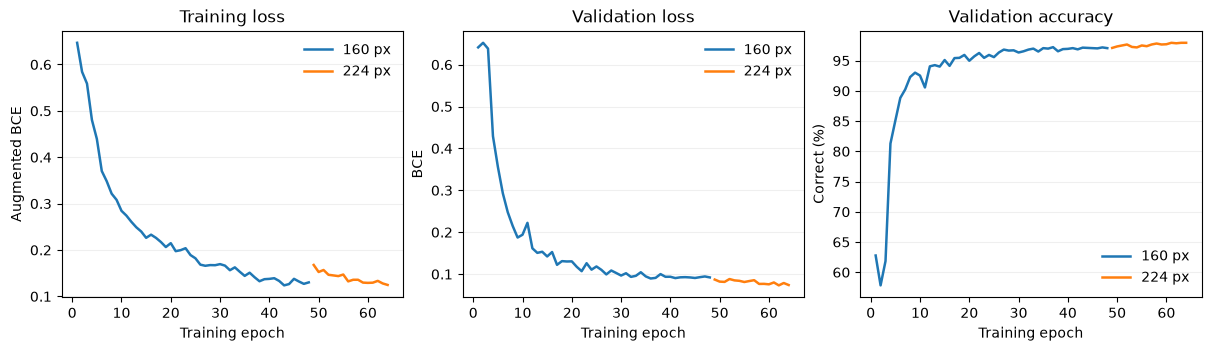

,Completed epochs,Best stage epoch,Validation correct,Validation accuracy,Validation BCE,Training and validation (min)
Size (px),,,,,,
160,48,37,2421,97.23%,0.09101,33.8
224,16,16,2439,97.95%,0.07397,28.9


In [6]:
import numpy as np
from IPython.display import Markdown

display(Markdown(
    "An initial FP16 run stopped during its second epoch after producing nonfinite validation scores. "
    "Training restarted from random weights with BF16 arithmetic on the RTX 3060, a zero bias and "
    "a weight standard deviation of 0.02 in the final linear layer, and gradient norms clipped to 5. "
    "The measurements below come from that restarted run."
))

histories=[]
elapsed_epochs=0
for size,epochs,_,_ in STAGES:
    history=pd.read_csv(RUN / f"history_{size}.csv")
    assert history.epoch.tolist()==list(range(1,epochs+1))
    history["training_epoch"]=history.epoch+elapsed_epochs
    histories.append(history)
    elapsed_epochs+=epochs

fig,axes=plt.subplots(1,3,figsize=(12,3.4),layout="constrained")
fields=[("train_loss","Training loss","Augmented BCE"),("val_bce","Validation loss","BCE"),
        ("val_accuracy","Validation accuracy","Correct (%)")]
for ax,(field,title,unit) in zip(axes,fields):
    for history in histories:
        size=int(history["size"].iloc[0])
        values=history[field]*(100 if field=="val_accuracy" else 1)
        ax.plot(history.training_epoch,values,label=f"{size} px",linewidth=1.8)
    ax.set(title=title,xlabel="Training epoch",ylabel=unit)
    ax.grid(axis="y",alpha=.2)
    ax.legend(frameon=False)
plt.show()

stage_results=[]
for history in histories:
    best=history.sort_values(["val_correct","val_bce"],ascending=[False,True]).iloc[0]
    stage_results.append({
        "Size (px)":int(best["size"]), "Completed epochs":len(history),
        "Best stage epoch":int(best.epoch),"Validation correct":int(best.val_correct),
        "Validation accuracy":f"{best.val_accuracy:.2%}","Validation BCE":round(best.val_bce,5),
        "Training and validation (min)":round(history.seconds.sum()/60,1),
    })
display(pd.DataFrame(stage_results).set_index("Size (px)"))

## Validation comparison
The image-level predictions are paired by filename. The comparison includes the earlier course classifier, standalone EfficientNet settings, and fixed combinations of their predictions. The validation table records both the best standalone EfficientNet setting and the entry chosen for the competition.

In [7]:
"""Validate course-trained classifiers and evaluate the locked contest entry."""
from pathlib import Path
import hashlib
import json

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms


INCUMBENT = 'Previous course CNN'
COURSE_WEIGHT_HASHES = {
    'course_scratch.pt': 'd39fc83699ca5cf23a32cc9c39f7f6a31ea23c37d200fc1f28c78cc6c58d79c0',
    'best_224.pt': '6d59ee721bc344c93a1902da170654d9eded7f45d7c8da0d8c9a04c83cda876e',
    'best_288.pt': 'ecaad6882833e3bb965d83d5135ac1560b4a89bb1e9af54600c8329d725562b1',
}
COURSE_SPLITS = {
    'val': (2490, '494cf087f7d2212e5bc6f2519d42eb3a51c9a6ea971042d5e768153505b61e3d'),
    'test': (2500, '007a91401bda0ce000878e4747bedf64c8793a146c54728dc56528b5f6ae892a'),
}
EFFICIENTNET_RECIPES = {
    INCUMBENT: {'incumbent': 1.},
    '224 whole image': {'plain224': 1.},
    '224 with horizontal flip': {'flip224': 1.},
    '192/224/256 with flips': {'multiscale': 1.},
    '224 whole image and corner crops': {'cropped': 1.},
    'Equal blend with multiscale EfficientNet': {'incumbent': .5,'multiscale': .5},
    'Equal blend with cropped EfficientNet': {'incumbent': .5,'cropped': .5},
    'All views, two-thirds EfficientNet': {'incumbent': 1/3,'multiscale': 1/3,'cropped': 1/3},
    'All views, two-thirds previous CNN': {'incumbent': 2/3,'multiscale': 1/6,'cropped': 1/6},
}


class CourseResidualBlock(nn.Module):
    def __init__(self, inputs, outputs, stride=1):
        super().__init__()
        self.main = nn.Sequential(nn.Conv2d(inputs, outputs, 3, stride, 1, bias=False),
                                  nn.BatchNorm2d(outputs), nn.ReLU(),
                                  nn.Conv2d(outputs, outputs, 3, padding=1, bias=False),
                                  nn.BatchNorm2d(outputs))
        self.skip = nn.Identity() if inputs == outputs and stride == 1 else nn.Sequential(
            nn.Conv2d(inputs, outputs, 1, stride, bias=False), nn.BatchNorm2d(outputs))

    def forward(self, x):
        return torch.relu(self.main(x) + self.skip(x))


class PreviousCourseCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, stride=2, padding=1, bias=False), nn.BatchNorm2d(32), nn.ReLU(),
            CourseResidualBlock(32, 32), CourseResidualBlock(32, 64, 2),
            CourseResidualBlock(64, 128, 2), CourseResidualBlock(128, 128),
            CourseResidualBlock(128, 256, 2), CourseResidualBlock(256, 256),
            nn.AdaptiveAvgPool2d(1), nn.Flatten())
        self.head = nn.Sequential(nn.Dropout(.2), nn.Linear(256, 1))

    def forward(self, x):
        return self.head(self.features(x)).squeeze(1)


def eval_digest(path):
    with Path(path).open('rb') as source:
        return hashlib.file_digest(source,'sha256').hexdigest()


def eval_write_json(path, content):
    pending = path.with_suffix('.json.tmp')
    pending.write_text(json.dumps(content,indent=2,allow_nan=False),encoding='utf-8')
    pending.replace(path)


def evaluation_checkpoints(run, reference_weights):
    config = json.loads((run/'config.json').read_text())
    complete = json.loads((run/'training_complete.json').read_text())
    if (config['architecture'] != 'EfficientNetV2-S' or config['pretrained'] is not False
            or config['train_images'] != 19995 or config['validation_images'] != 2490
            or complete['epochs'] != sum(stage[1] for stage in config['stages'])
            or complete['final_checkpoint'] != 'best_224.pt'):
        raise ValueError('Expected completed EfficientNetV2-S training on the course split.')
    for size, epochs, _, _ in config['stages']:
        history = pd.read_csv(run/f'history_{size}.csv')
        if history.epoch.tolist() != list(range(1,epochs+1)):
            raise ValueError(f'Incomplete {size}-pixel training history.')
    for file, digest in COURSE_WEIGHT_HASHES.items():
        if eval_digest(reference_weights/file) != digest:
            raise ValueError(f'Previous course checkpoint has changed: {file}')
    return dict(reference=COURSE_WEIGHT_HASHES, efficientnet=eval_digest(run/'best_224.pt'),
                training_config=eval_digest(run/'config.json'))


def eval_open_model(path, device, *, efficient=False, original=False):
    state = torch.load(path,map_location='cpu',weights_only=True)
    if efficient:
        if state['size'] != 224 or state['config'] != json.loads((path.parent/'config.json').read_text()):
            raise ValueError('EfficientNet checkpoint metadata differs from training.')
        model = models.efficientnet_v2_s(weights=None,num_classes=1)
    else:
        model = PreviousCourseCNN()
    model.load_state_dict(state['state_dict'])
    layout = torch.contiguous_format if original else torch.channels_last
    return model.to(device=device,memory_format=layout).eval()


def eval_split(root, split, size):
    data = datasets.ImageFolder(root/split,transforms.Compose([
        transforms.Resize((size,size)),transforms.PILToTensor()]))
    paths = [Path(p).relative_to(root).as_posix() for p,_ in data.samples]
    labels = np.array(data.targets,dtype=np.int64)
    identity = ''.join(f'{p}\t{y}\n' for p,y in zip(paths,labels)).encode()
    count, expected_hash = COURSE_SPLITS[split]
    if (data.class_to_idx != {'cats':0,'dogs':1} or len(paths)!=count
            or len(set(paths))!=count or hashlib.sha256(identity).hexdigest()!=expected_hash):
        raise ValueError(f'{split} filenames or class labels differ from the course data.')
    return data, paths, labels


@torch.inference_mode()
def eval_views(model, dataset, size, device, views, *, original=False, batch_size=64, efficient=False):
    parts = {name:[] for name in views}
    dtype = torch.bfloat16 if efficient else torch.float16
    use_amp = device.type=='cuda' and (not efficient or torch.cuda.is_bf16_supported())
    for raw,_ in DataLoader(dataset,batch_size=batch_size,num_workers=0,shuffle=False):
        if original:
            x = raw.float().div_(255).sub_(.5).div_(.5).to(device)
        else:
            x = raw.to(device).float().div_(127.5).sub_(1).contiguous(memory_format=torch.channels_last)
        with torch.autocast(device.type,dtype=dtype,enabled=use_amp):
            direct = model(x).flatten()
            if 'plain' in views:
                parts['plain'].append(direct.float().cpu())
            if 'flip' in views or 'corners' in views:
                mirror = model(x.flip(-1)).flatten()
                # The original 128/160-pixel model averaged flips in its forward-pass precision.
                averaged = ((direct+mirror)/2).float() if original else (direct.float()+mirror.float())/2
                if 'flip' in views:
                    parts['flip'].append(averaged.cpu())
                if 'corners' in views:
                    edge = round(size*.78)
                    crops = []
                    for top in (0,size-edge):
                        for left in (0,size-edge):
                            window = x[:,:,top:top+edge,left:left+edge]
                            window = F.interpolate(window,size=(size,size),mode='bilinear',align_corners=False)
                            normal = model(window).flatten().float()
                            flipped = model(window.flip(-1)).flatten().float()
                            crops.append((normal+flipped)/2)
                    parts['corners'].append(((averaged+torch.stack(crops).mean(0))/2).cpu())
    values = {name:torch.cat(rows) for name,rows in parts.items()}
    if any(len(z)!=len(dataset) or not torch.isfinite(z).all() for z in values.values()):
        raise ValueError('Invalid image predictions.')
    return values


def eval_components(root, split, run, weights, names, device):
    """Compute each requested component on identically ordered, unshuffled images."""
    _, paths, labels = eval_split(root,split,224)
    def images(size):
        data,p,y = eval_split(root,split,size)
        assert p==paths and np.array_equal(labels,y)
        return data
    columns = {}
    if 'incumbent' in names:
        base = eval_open_model(weights/'course_scratch.pt',device,original=True)
        old = [eval_views(base,images(s),s,device,{'flip'},original=True,batch_size=128)['flip'] for s in (128,160)]
        medium = eval_open_model(weights/'best_224.pt',device)
        medium_z = eval_views(medium,images(224),224,device,{'flip'})['flip']
        large = eval_open_model(weights/'best_288.pt',device)
        large_z = eval_views(large,images(288),288,device,{'corners'})['corners']
        columns['incumbent'] = (4*large_z+torch.stack(old).mean(0)+medium_z)/6
        del base,medium,large
    if set(names)-{'incumbent'}:
        model = eval_open_model(run/'best_224.pt',device,efficient=True)
        views = set()
        if 'plain224' in names:
            views.add('plain')
        if 'flip224' in names or 'multiscale' in names:
            views.add('flip')
        if 'cropped' in names:
            views.add('corners')
        middle = eval_views(model,images(224),224,device,views,batch_size=32,efficient=True)
        for component, view in [('plain224','plain'),('flip224','flip'),('cropped','corners')]:
            if component in names:
                columns[component] = middle[view]
        if 'multiscale' in names:
            small,large = [eval_views(model,images(s),s,device,{'flip'},batch_size=32,efficient=True)['flip'] for s in (192,256)]
            columns['multiscale'] = torch.stack([small,middle['flip'],large]).mean(0)
    frame = pd.DataFrame({'path':paths,'target':labels})
    for name,z in columns.items():
        frame[name] = z.numpy()
    return frame


def eval_recipe_logits(frame, name):
    proportions = EFFICIENTNET_RECIPES[name]
    return sum(weight*frame[key].to_numpy(dtype=np.float64) for key,weight in proportions.items())


def eval_accuracy(logits, targets):
    correct = int(np.sum((logits>=0)==targets))
    bce = float(np.logaddexp(0,(1-2*targets)*logits).mean())
    return dict(correct=correct,total=len(targets),accuracy=correct/len(targets),bce=bce)


def eval_choose(rows):
    reference = next(row for row in rows if row['name']==INCUMBENT)
    challenger = min((row for row in rows if row['name']!=INCUMBENT),
                     key=lambda row:(-row['correct'],row['bce']))
    selected = challenger if challenger['correct']>reference['correct'] else reference
    return selected, challenger


def eval_validation_rows(frame):
    targets = frame.target.to_numpy()
    rows = []
    for name in EFFICIENTNET_RECIPES:
        logits = eval_recipe_logits(frame,name)
        matches = (logits>=0)==targets
        rows.append(dict(name=name,**eval_accuracy(logits,targets),
                         cats_correct=int(matches[targets==0].sum()),dogs_correct=int(matches[targets==1].sum())))
    return rows


def select_efficientnet(root, run, reference_weights, device=None):
    """Lock the most accurate validation recipe. Incumbent wins equal-count comparisons."""
    root,run,weights = Path(root),Path(run),Path(reference_weights)
    device = torch.device(device or ('cuda' if torch.cuda.is_available() else 'cpu'))
    checkpoint_hashes = evaluation_checkpoints(run,weights)
    required = set().union(*(combination.keys() for combination in EFFICIENTNET_RECIPES.values()))
    frame = eval_components(root,'val',run,weights,required,device)
    path = run/'eval_validation.csv'
    frame.to_csv(path,index=False,float_format='%.12g')
    rows = eval_validation_rows(pd.read_csv(path))
    selected,challenger = eval_choose(rows)
    lock = dict(selected=selected['name'],challenger=challenger['name'],validation=selected,
                challenger_validation=challenger,candidates=rows,recipes=EFFICIENTNET_RECIPES,threshold=.5,
                rule='Most validation images correct. Lower BCE resolves challenger ties. Incumbent retains equal counts.',
                checkpoint_hashes=checkpoint_hashes,validation_predictions_sha256=eval_digest(path))
    eval_write_json(run/'eval_selection.json',lock)
    return lock


def test_selected_efficientnet(root, run, reference_weights, device=None):
    """Score the single validation winner, or retain the documented previous score."""
    root,run,weights = Path(root),Path(run),Path(reference_weights)
    selection_path = run/'eval_selection.json'
    lock = json.loads(selection_path.read_text())
    rows = eval_validation_rows(pd.read_csv(run/'eval_validation.csv'))
    selected,challenger = eval_choose(rows)
    if (rows!=lock['candidates'] or selected!=lock['validation'] or challenger!=lock['challenger_validation']
            or selected['name']!=lock['selected'] or challenger['name']!=lock['challenger']
            or lock['recipes']!=EFFICIENTNET_RECIPES or lock['threshold']!=.5
            or lock['validation_predictions_sha256']!=eval_digest(run/'eval_validation.csv')
            or evaluation_checkpoints(run,weights)!=lock['checkpoint_hashes']):
        raise ValueError('The saved validation decision or its inputs have changed.')
    name = lock['selected']
    report = dict(selected=name,challenger=lock['challenger'],selection_sha256=eval_digest(selection_path),
                  validation=selected,challenger_validation=challenger,target_correct=2473)
    if name==INCUMBENT:
        report.update(new_test=False,correct=2449,total=2500,accuracy=2449/2500,
                      bce=.08941727131605148,gained_vs_previous=0,lost_vs_previous=0,
                      predictions_file=None,source='Recorded course test result of 288 with original context')
    else:
        device = torch.device(device or ('cuda' if torch.cuda.is_available() else 'cpu'))
        required = set(EFFICIENTNET_RECIPES[name])|{'incumbent'}
        frame = eval_components(root,'test',run,weights,required,device)
        logits = eval_recipe_logits(frame,name)
        target = frame.target.to_numpy()
        matches = (logits>=0)==target
        baseline = (frame.incumbent.to_numpy()>=0)==target
        frame['logit'] = logits
        frame['prediction'] = (logits>=0).astype(int)
        path = run/'eval_test.csv'
        frame.to_csv(path,index=False,float_format='%.12g')
        report.update(**eval_accuracy(logits,target),new_test=True,reference_recomputed_correct=int(baseline.sum()),
                      gained_vs_previous=int(np.sum(matches & ~baseline)),
                      lost_vs_previous=int(np.sum(~matches & baseline)),
                      predictions_file=path.name,predictions_sha256=eval_digest(path))
    report['exceeds_0_9888'] = bool(report['correct']>=report['target_correct'])
    eval_write_json(run/'eval_test.json',report)
    return report

In [8]:
decision=select_efficientnet(DATA_ROOT,RUN,REFERENCE_WEIGHTS)
scores=pd.DataFrame(decision["candidates"]).set_index("name")
display(scores.style.format({"accuracy":"{:.2%}","bce":"{:.5f}"}))
standalone=[r for r in decision["candidates"] if "incumbent" not in decision["recipes"][r["name"]]]
best_eff=min(standalone,key=lambda row:(-row["correct"],row["bce"]))
print(f"Best standalone EfficientNet setting: {best_eff['name']}, "
      f"{best_eff['correct']:,}/{best_eff['total']:,} ({best_eff['accuracy']:.2%}).")
print("Selected entry:",decision["selected"])

,correct,total,accuracy,bce,cats_correct,dogs_correct
name,,,,,,
Previous course CNN,2446,2490,98.23%,0.08259,1212,1234
224 whole image,2439,2490,97.95%,0.07397,1210,1229
224 with horizontal flip,2442,2490,98.07%,0.06705,1211,1231
192/224/256 with flips,2442,2490,98.07%,0.06438,1209,1233
224 whole image and corner crops,2449,2490,98.35%,0.06072,1219,1230
Equal blend with multiscale EfficientNet,2447,2490,98.27%,0.06505,1215,1232
Equal blend with cropped EfficientNet,2450,2490,98.39%,0.06465,1218,1232
"All views, two-thirds EfficientNet",2449,2490,98.35%,0.06209,1216,1233
"All views, two-thirds previous CNN",2449,2490,98.35%,0.06840,1213,1236


Best standalone EfficientNet setting: 224 whole image and corner crops, 2,449/2,490 (98.35%).
Selected entry: Equal blend with cropped EfficientNet


## Course test benchmark
The competition uses the same test split as earlier course experiments. The selected model and inference settings are fixed on validation before the final decision. If the previous classifier is retained, the table reports its previously measured test accuracy.

In [9]:
report=test_selected_efficientnet(DATA_ROOT,RUN,REFERENCE_WEIGHTS)
source="Newly evaluated test result" if report["new_test"] else "Previously measured test result"
print(f"{source}: {report['selected']}, {report['correct']:,}/{report['total']:,} ({report['accuracy']:.2%}).")
if report["new_test"]:
    print(f"Compared with the reference on the same images: {report['gained_vs_previous']} errors corrected, "
          f"{report['lost_vs_previous']} new errors.")

Newly evaluated test result: Equal blend with cropped EfficientNet, 2,452/2,500 (98.08%).
Compared with the reference on the same images: 18 errors corrected, 15 new errors.


## Result
The best standalone EfficientNet classified **2,449/2,490 (98.35%)** on validation with 224 whole image and corner crops. The validation-selected entry **Equal blend with cropped EfficientNet** classified **2,452/2,500 (98.08%)** on the course test set. It corrected 18 errors and introduced 15 relative to the reference classifier on those images.